# BatchNorm 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week09/batchnorm/lab/batchnorm.ipynb)

미니배치마다 뉴런별로 평균 0 · 표준편차 1, 그다음 γ · β.

- **파트 1**: BatchNorm 직접 구현 → 2, 4, 6, 8 재현, `nn.BatchNorm1d` 와 비교
- **파트 2**: 시그모이드 8층: 층별 퍼짐과 학습 곡선
- **파트 3**: `train()` / `eval()` 과 모아 둔 평균

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. 직접 구현

$$\hat x = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \qquad y = \gamma \hat x + \beta$$

In [ ]:
def batchnorm(x, gamma, beta, eps=1e-5):
    mu = x.mean(axis=0)                                   # per neuron (column)
    var = x.var(axis=0)                                   # population variance (divide by m)
    x_hat = None  # TODO: normalize
    return gamma * x_hat + beta

x = np.array([[2.0], [4.0], [6.0], [8.0]])               # one neuron, batch of 4
print("normalized:", batchnorm(x, 1.0, 0.0).ravel().round(2))
print("gamma=2, beta=1:", batchnorm(x, 2.0, 1.0).ravel().round(2))

bn = nn.BatchNorm1d(1); bn.train()
print("nn.BatchNorm1d:", bn(torch.tensor(x, dtype=torch.float32)).detach().numpy().ravel().round(2))

**예상 결과**

```
normalized: [-1.34 -0.45  0.45  1.34]
gamma=2, beta=1: [-1.68  0.11  1.89  3.68]
nn.BatchNorm1d: [-1.34 -0.45  0.45  1.34]
```

## 파트 2. 시그모이드 8층

손글씨 숫자 1,797장. 먼저 학습 전 층별로 '그림 사이의 퍼짐' 을 재고, 그다음 SGD (lr 0.5, 배치 64) 로 1,500번 학습한다.

In [ ]:
from sklearn.datasets import load_digits
d = load_digits()
X = torch.tensor(d.data / 16.0, dtype=torch.float32); y = torch.tensor(d.target)

def make_net(use_bn, depth=8, width=64):
    layers, i = [], 64
    for _ in range(depth):
        layers += [nn.Linear(i, width)] + ([None] if use_bn else []) + [nn.Sigmoid()]  # TODO: the BatchNorm layer
        i = width
    return nn.Sequential(*layers, nn.Linear(width, 10))

def spreads(net, X):
    out, h = [], X
    for m in net:
        if isinstance(m, nn.Sigmoid):
            out.append(h.std(0).mean().item())           # spread across images of what enters the sigmoid
        h = m(h)
    return out

for use_bn in [False, True]:
    torch.manual_seed(0); net = make_net(use_bn); net.train()
    with torch.no_grad():
        s = spreads(net, X[:512])
    print("BN   " if use_bn else "plain", ["%.1e" % v for v in s])

**예상 결과**

```
plain ['1.5e-01', '2.1e-02', '3.0e-03', '4.4e-04', '5.9e-05', '8.3e-06', '1.2e-06', '1.8e-07']
BN    ['1.0e+00', '1.0e+00', '1.0e+00', '1.0e+00', '1.0e+00', '1.0e+00', '1.0e+00', '1.0e+00']
```

In [ ]:
def train(net, X, y, steps=1500, lr=0.5, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.SGD(net.parameters(), lr); curve = []
    for it in range(steps + 1):
        if it % 50 == 0:
            net.eval()
            with torch.no_grad():
                curve.append((net(X).argmax(1) == y).float().mean().item())
            net.train()
        idx = torch.randint(0, len(X), (64,), generator=g)
        opt.zero_grad(); nn.functional.cross_entropy(net(X[idx]), y[idx]).backward(); opt.step()
    return curve

curves = {}
for use_bn in [False, True]:
    torch.manual_seed(0); curves[use_bn] = train(make_net(use_bn), X, y)
    print("BN" if use_bn else "plain", " accuracy at 250:", round(curves[use_bn][5], 3), " at 1500:", round(curves[use_bn][-1], 3))
steps = np.arange(0, 1501, 50)
plt.plot(steps, curves[False], label="plain"); plt.plot(steps, curves[True], label="BatchNorm")
plt.xlabel("step"); plt.ylabel("accuracy"); plt.legend(); plt.show()

**예상 결과**

```
plain  accuracy at 250: 0.101  at 1500: 0.098
BN  accuracy at 250: 0.967  at 1500: 0.999
```

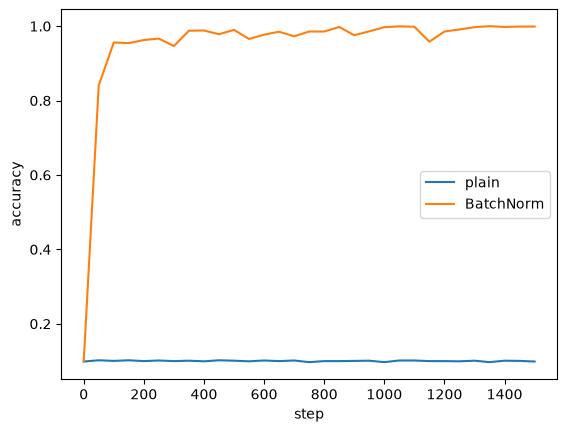

## 파트 3. 시험 모드: 모아 둔 평균

In [ ]:
torch.manual_seed(0); net = make_net(True); train(net, X, y, steps=500)
first_bn = net[1]
print("running mean (first 5 neurons):", first_bn.running_mean[:5].numpy().round(2))
one = X[:1]
net.eval()
with torch.no_grad():
    p_eval = None  # TODO: predict one image in eval mode
print("eval mode prediction:", p_eval, " true:", y[0].item())
net.train()
try:
    net(one)
except Exception as e:
    print("train mode with one image ->", type(e).__name__, ":", str(e)[:80])

**예상 결과**

```
running mean (first 5 neurons): [-0.22  0.22  0.04 -0.33  0.13]
eval mode prediction: 0  true: 0
train mode with one image -> ValueError : Expected more than 1 value per channel when training, got input size torch.Size(
```

**확인 질문**
1. 파트 1 에서 직접 구현한 값과 `nn.BatchNorm1d` 의 값이 같은가? (`var` 를 m 으로 나누는지 m−1 로 나누는지 확인)
2. 파트 2 에서 BatchNorm 없는 신경망의 층별 퍼짐은 층마다 대략 몇 분의 1 로 줄어드나?
3. 파트 2 에서 활성 함수를 ReLU 로 바꾸면 BatchNorm 없이도 학습되나?
4. 파트 3 에서 train 모드로 그림 한 장을 넣으면 왜 오류가 나나?

데이터 출처: Alpaydin & Kaynak, Optical Recognition of Handwritten Digits, UCI (scikit-learn `load_digits`) · Ioffe & Szegedy (2015) arXiv:1502.03167.